# Улучшение baseline-модели прогнозирования стоимости недвижимости

**Проект:** Яндекс Недвижимость, задача регрессии `price`.  
**Цель:** улучшить MAE, RMSE и R² baseline-модели, сохранив воспроизводимость экспериментов в MLflow.  
**Данные:** очищенная таблица `flats_buildings_clean` из предыдущего проекта (123 525 объектов).

В одном эксперименте MLflow последовательно выполняются пять этапов: регистрация baseline, EDA,
генерация признаков, отбор признаков и оптимизация гиперпараметров. Все четыре модели
регистрируются под именем `real_estate_price_model`.

## 0. Настройка окружения и воспроизводимое разбиение

Перед запуском нужно выполнить `python mlflow_server/register_baseline.py`, как описано в README.
Ноутбук использует то же разбиение train/test, что и baseline: 80%/20%, `random_state=42`.
Отбор признаков и подбор гиперпараметров выполняются только на train; test используется для итоговой оценки каждой версии.

In [1]:
# Стандартные библиотеки и настройка путей проекта.
import json
import os
import sys
import time
import warnings
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import mlflow
import mlflow.sklearn
import numpy as np
import optuna
import pandas as pd
import seaborn as sns
from autofeat import AutoFeatRegressor
from dotenv import load_dotenv
from mlflow.models.signature import infer_signature
from mlxtend.feature_selection import SequentialFeatureSelector
from optuna.integration import MLflowCallback
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import KFold, RandomizedSearchCV, cross_val_score
from sklearn.pipeline import FeatureUnion, Pipeline
from sklearn.preprocessing import KBinsDiscretizer, OneHotEncoder, PolynomialFeatures

PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "model_improvement" else Path.cwd()
sys.path.insert(0, str(PROJECT_ROOT))
from model_improvement.utils import (
    ARTIFACTS_DIR, CATEGORICAL_COLS, load_data, log_environment,
    regression_metrics, save_json, split_data,
)

load_dotenv(PROJECT_ROOT / ".env")
load_dotenv(PROJECT_ROOT / "local-emulation.env")
ARTIFACTS_DIR.mkdir(parents=True, exist_ok=True)
warnings.filterwarnings("ignore", category=FutureWarning)
sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (10, 6)

RANDOM_STATE = int(os.getenv("RANDOM_STATE", "42"))
FAST_RUN = os.getenv("FAST_RUN", "false").lower() == "true"
N_TRIALS = 3 if FAST_RUN else 20
N_ITER = 3 if FAST_RUN else 15
CANDIDATE_COUNT = 12 if FAST_RUN else 25
SELECTED_COUNT = 6 if FAST_RUN else 10
SELECTION_SAMPLE_SIZE = 2_000 if FAST_RUN else 5_000
SEARCH_SAMPLE_SIZE = 10_000 if FAST_RUN else 25_000
N_ESTIMATORS = 30 if FAST_RUN else 100

# Для сдачи адрес берётся из .env: http://127.0.0.1:5000.
# SQLite используется только как локальная проверка без облачной инфраструктуры.
tracking_uri = os.getenv("MLFLOW_TRACKING_URI", f"sqlite:///{PROJECT_ROOT / 'mlflow.db'}")
mlflow.set_tracking_uri(tracking_uri)
EXPERIMENT_NAME = os.getenv("MLFLOW_EXPERIMENT_NAME", "real_estate_price_improvement")
MODEL_NAME = os.getenv("MLFLOW_MODEL_NAME", "real_estate_price_model")
experiment = mlflow.set_experiment(EXPERIMENT_NAME)
NOTEBOOK_PATH = PROJECT_ROOT / "model_improvement" / "model_improvement.ipynb"

print(f"MLflow: {mlflow.get_tracking_uri()}")
print(f"Experiment: {EXPERIMENT_NAME}, id={experiment.experiment_id}")
print(f"FAST_RUN={FAST_RUN}; trials={N_TRIALS}; random search iterations={N_ITER}")

/Users/natasa/Documents/Магистратура/MlOps_baseline/.venv/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


2026-11-14 18:16:47,506 INFO: setup plugin alembic.autogenerate.schemas


2026-11-14 18:16:47,509 INFO: setup plugin alembic.autogenerate.tables


2026-11-14 18:16:47,510 INFO: setup plugin alembic.autogenerate.types


2026-11-14 18:16:47,513 INFO: setup plugin alembic.autogenerate.constraints


2026-11-14 18:16:47,514 INFO: setup plugin alembic.autogenerate.defaults


2026-11-14 18:16:47,516 INFO: setup plugin alembic.autogenerate.comments


2026-11-14 18:16:47,518 INFO: setup plugin alembic.ext.checkconstraint_byname


2026-11-14 18:16:48,083 INFO: Context impl SQLiteImpl.


2026-11-14 18:16:48,084 INFO: Will assume non-transactional DDL.


MLflow: sqlite:////Users/natasa/Documents/Магистратура/MlOps_baseline/mlflow_verified.db
Experiment: real_estate_price_improvement, id=1
FAST_RUN=False; trials=20; random search iterations=15


In [2]:
# Загружаем очищенные данные и повторяем разбиение baseline.
data_path = PROJECT_ROOT / os.getenv("DATA_PATH", "data/initial_data.csv")
df = load_data(data_path)
X_train, X_test, y_train, y_test = split_data(df, random_state=RANDOM_STATE)

baseline_path = PROJECT_ROOT / os.getenv("BASELINE_MODEL_PATH", "baseline/model.pkl")
baseline_model = joblib.load(baseline_path)
baseline_predictions = baseline_model.predict(X_test)
baseline_metrics = regression_metrics(y_test, baseline_predictions)

print(f"Всего строк: {len(df):,}; train: {len(X_train):,}; test: {len(X_test):,}")
print("Baseline:", json.dumps(baseline_metrics, ensure_ascii=False, indent=2))
assert list(X_train.columns) == list(X_test.columns)
assert not X_train.index.intersection(X_test.index).any()

Всего строк: 123,525; train: 98,820; test: 24,705
Baseline: {
  "mae": 2003737.1546692452,
  "rmse": 2721365.778902152,
  "r2": 0.7749163851066123
}


## Этап 1. MLflow Tracking Server и Model Registry

Инфраструктура запускается вне ноутбука скриптом `mlflow_server/run_mlflow.sh`: PostgreSQL хранит
эксперименты и реестр, S3 — артефакты. Скрипт `mlflow_server/register_baseline.py` логирует
baseline с параметрами, метриками, сигнатурой, окружением и регистрирует первую версию модели.
Текущий ноутбук подключается к тому же эксперименту, поэтому все последующие запуски оказываются рядом.

## Этап 2. Исследовательский анализ данных (EDA)

### 2.1. Структура, типы и качество данных

Данные уже очищены Airflow-пайплайном предыдущего проекта. Здесь дополнительно проверяем дубли,
пропуски, типы и диапазоны, но не удаляем строки по test-признакам и не меняем выборку.

In [3]:
# Общий обзор: размер, типы, пропуски, дубли и описательные статистики.
print("Размер датасета:", df.shape)
display(df.head())
display(df.dtypes.rename("dtype").to_frame())
missing = df.isna().sum().rename("missing").to_frame()
missing["missing_pct"] = 100 * missing["missing"] / len(df)
display(missing)
print("Дубли id:", int(df["id"].duplicated().sum()))
print("Полные дубли строк:", int(df.duplicated().sum()))
display(df.describe().T)

quality_summary = {
    "rows": len(df), "columns": len(df.columns),
    "missing_cells": int(df.isna().sum().sum()),
    "duplicate_ids": int(df["id"].duplicated().sum()),
    "feature_count": X_train.shape[1],
}
save_json(quality_summary, ARTIFACTS_DIR / "eda_quality.json")

Размер датасета: (123525, 18)


,id,building_id,floor,kitchen_area,living_area,rooms,is_apartment,studio,total_area,price,build_year,building_type_int,latitude,longitude,ceiling_height,flats_count,floors_total,has_elevator
0,0,6220,9,9.9,19.900000,1,0,0,35.099998,9500000,1965,6,55.717113,37.781120,2.64,84,12,1
1,1,18012,7,8.5,16.600000,1,0,0,43.000000,13500000,2001,2,55.794849,37.608013,3.00,97,10,1
2,2,17821,9,9.0,32.000000,2,0,0,56.000000,13500000,2000,4,55.740040,37.761742,2.70,80,10,1
3,3,18579,1,10.1,43.099998,3,0,0,76.000000,20000000,2002,4,55.672016,37.570877,2.64,771,17,1
4,4,9293,3,3.0,14.000000,1,0,0,24.000000,5200000,1971,1,55.808807,37.707306,2.60,208,9,1


,dtype
id,int64
building_id,int64
floor,int64
kitchen_area,float64
living_area,float64
rooms,int64
is_apartment,int64
studio,int64
total_area,float64
price,int64


,missing,missing_pct
id,0,0.0
building_id,0,0.0
floor,0,0.0
kitchen_area,0,0.0
living_area,0,0.0
rooms,0,0.0
is_apartment,0,0.0
studio,0,0.0
total_area,0,0.0
price,0,0.0


Дубли id: 0
Полные дубли строк: 0


,count,mean,std,min,25%,50%,75%,max
id,123525.0,7.008759e+04,4.104925e+04,0.000000e+00,3.432200e+04,7.026400e+04,1.052860e+05,1.413610e+05
building_id,123525.0,1.377163e+04,6.646489e+03,4.000000e+00,8.522000e+03,1.365200e+04,1.963500e+04,2.462000e+04
floor,123525.0,7.264829e+00,5.323996e+00,1.000000e+00,3.000000e+00,6.000000e+00,1.000000e+01,5.500000e+01
kitchen_area,123525.0,9.052734e+00,3.035239e+00,1.500000e+00,7.000000e+00,8.900000e+00,1.000000e+01,1.020000e+02
living_area,123525.0,3.130897e+01,1.185419e+01,2.000000e+00,2.000000e+01,3.040000e+01,4.000000e+01,1.073000e+02
rooms,123525.0,1.962720e+00,8.166056e-01,1.000000e+00,1.000000e+00,2.000000e+00,3.000000e+00,6.000000e+00
is_apartment,123525.0,9.026513e-03,9.457858e-02,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,1.000000e+00
studio,123525.0,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00
total_area,123525.0,5.287768e+01,1.682187e+01,1.280000e+01,3.880000e+01,5.040000e+01,6.300000e+01,1.040000e+02
price,123525.0,1.247813e+07,5.681144e+06,3.390000e+06,8.600000e+06,1.100000e+07,1.450000e+07,4.450000e+07


### 2.2. Распределение целевой переменной и основных числовых признаков

Логарифм цены показываем только для анализа: модель обучается на исходной цене, поэтому метрики
остаются в рублях и напрямую сравнимы с baseline.

In [4]:
# Четыре распределения помогают увидеть асимметрию и масштаб признаков.
fig, axes = plt.subplots(2, 2, figsize=(15, 10))
sns.histplot(df["price"] / 1e6, bins=50, ax=axes[0, 0])
axes[0, 0].set(title="Распределение цены", xlabel="Цена, млн руб.")
sns.histplot(np.log1p(df["price"]), bins=50, ax=axes[0, 1])
axes[0, 1].set(title="Распределение log1p(price)", xlabel="log1p(price)")
sns.histplot(df["total_area"], bins=50, ax=axes[1, 0])
axes[1, 0].set(title="Общая площадь", xlabel="м²")
sns.histplot(df["rooms"], bins=np.arange(0.5, df["rooms"].max() + 1.5, 1), ax=axes[1, 1])
axes[1, 1].set(title="Количество комнат", xlabel="комнаты")
plt.tight_layout()
fig.savefig(ARTIFACTS_DIR / "eda_distributions.png", dpi=150, bbox_inches="tight")
plt.show()

<Figure size 1500x1000 with 4 Axes>

### 2.3. Корреляции и взаимодействие признаков с ценой

`building_type_int` — закодированная категория, а не непрерывная величина. Его коэффициент корреляции
можно использовать как сигнал связи, но нельзя интерпретировать как физическую линейную зависимость.
Идентификаторы `id` и `building_id` из матрицы исключены, поскольку в модель они не входят.

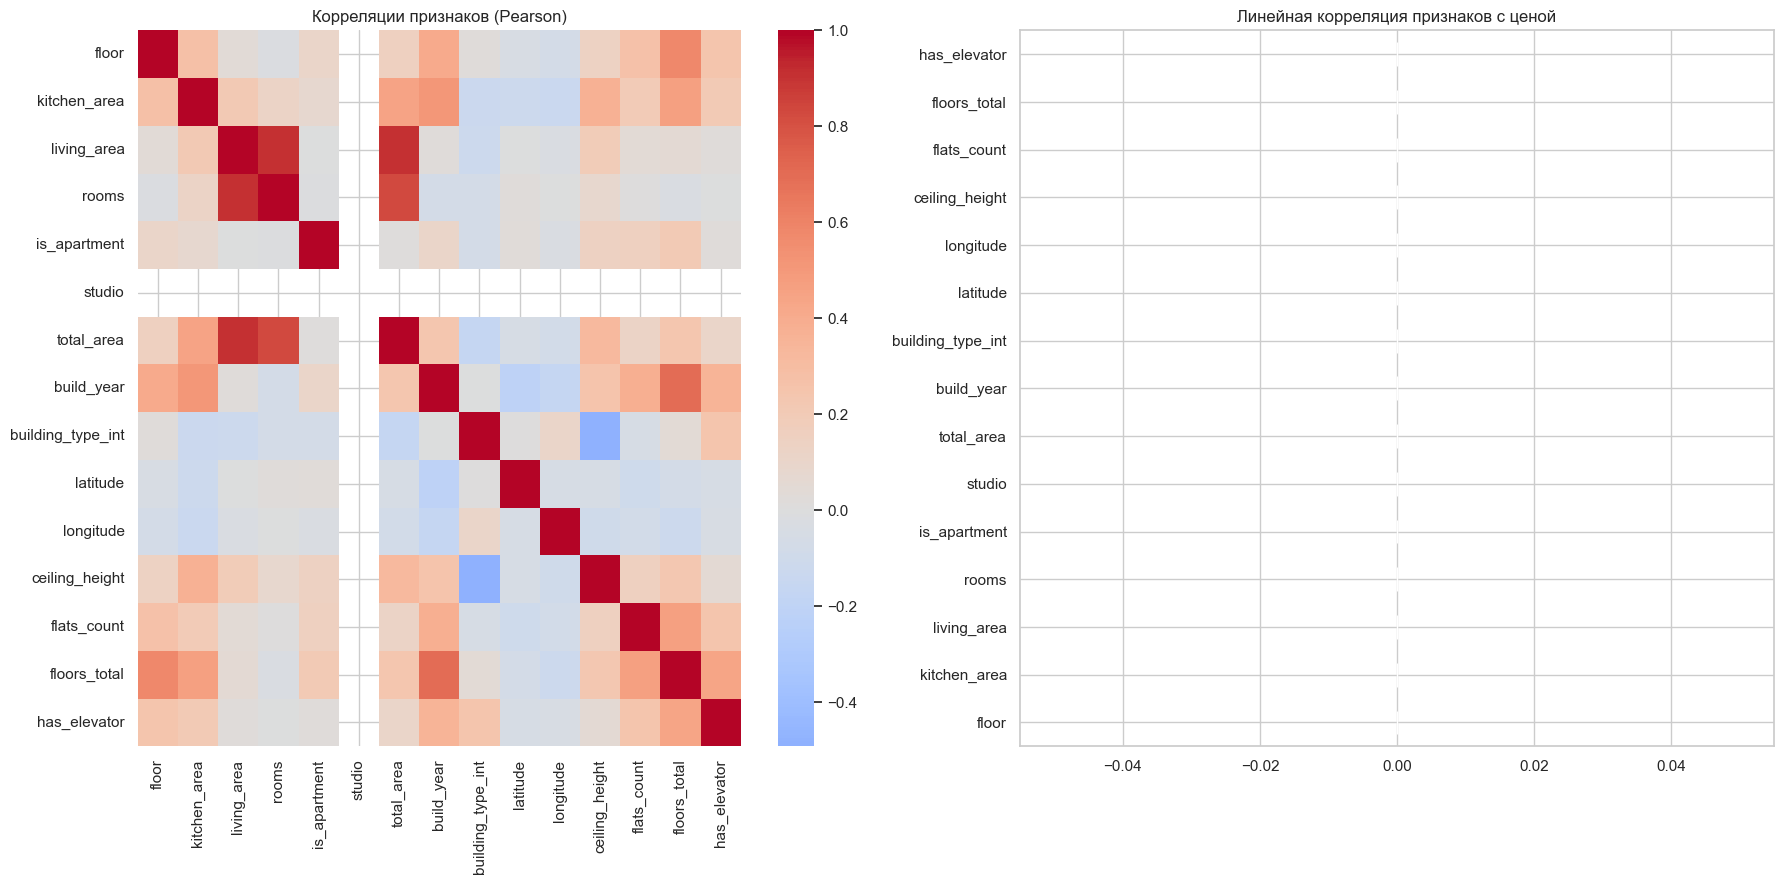

,pearson_with_price,spearman_with_price
floor,NaN,0.140028
kitchen_area,NaN,0.372044
living_area,NaN,0.628371
rooms,NaN,0.583232
is_apartment,NaN,0.056220
studio,NaN,NaN
total_area,NaN,0.691891
build_year,NaN,0.136102
building_type_int,NaN,-0.235391
latitude,NaN,0.045712


In [5]:
# Pearson показывает линейные связи; Spearman дополнительно проверяет монотонные нелинейные связи.
numeric_for_eda = df[X_train.columns].select_dtypes(include=np.number)
pearson = numeric_for_eda.corr(numeric_only=True)
price_corr = pearson.join(df[["price"]]).corr()["price"].drop("price").sort_values()
spearman_price = numeric_for_eda.join(df[["price"]]).corr(method="spearman")["price"].drop("price")

fig, axes = plt.subplots(1, 2, figsize=(18, 9))
sns.heatmap(pearson, cmap="coolwarm", center=0, ax=axes[0])
axes[0].set_title("Корреляции признаков (Pearson)")
price_corr.sort_values().plot.barh(ax=axes[1], color="steelblue")
axes[1].set_title("Линейная корреляция признаков с ценой")
plt.tight_layout()
fig.savefig(ARTIFACTS_DIR / "eda_correlations.png", dpi=150, bbox_inches="tight")
plt.show()

display(pd.DataFrame({"pearson_with_price": price_corr, "spearman_with_price": spearman_price}).sort_values("pearson_with_price"))

2026-11-14 18:16:59,578 INFO: Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.


2026-11-14 18:16:59,764 INFO: Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.


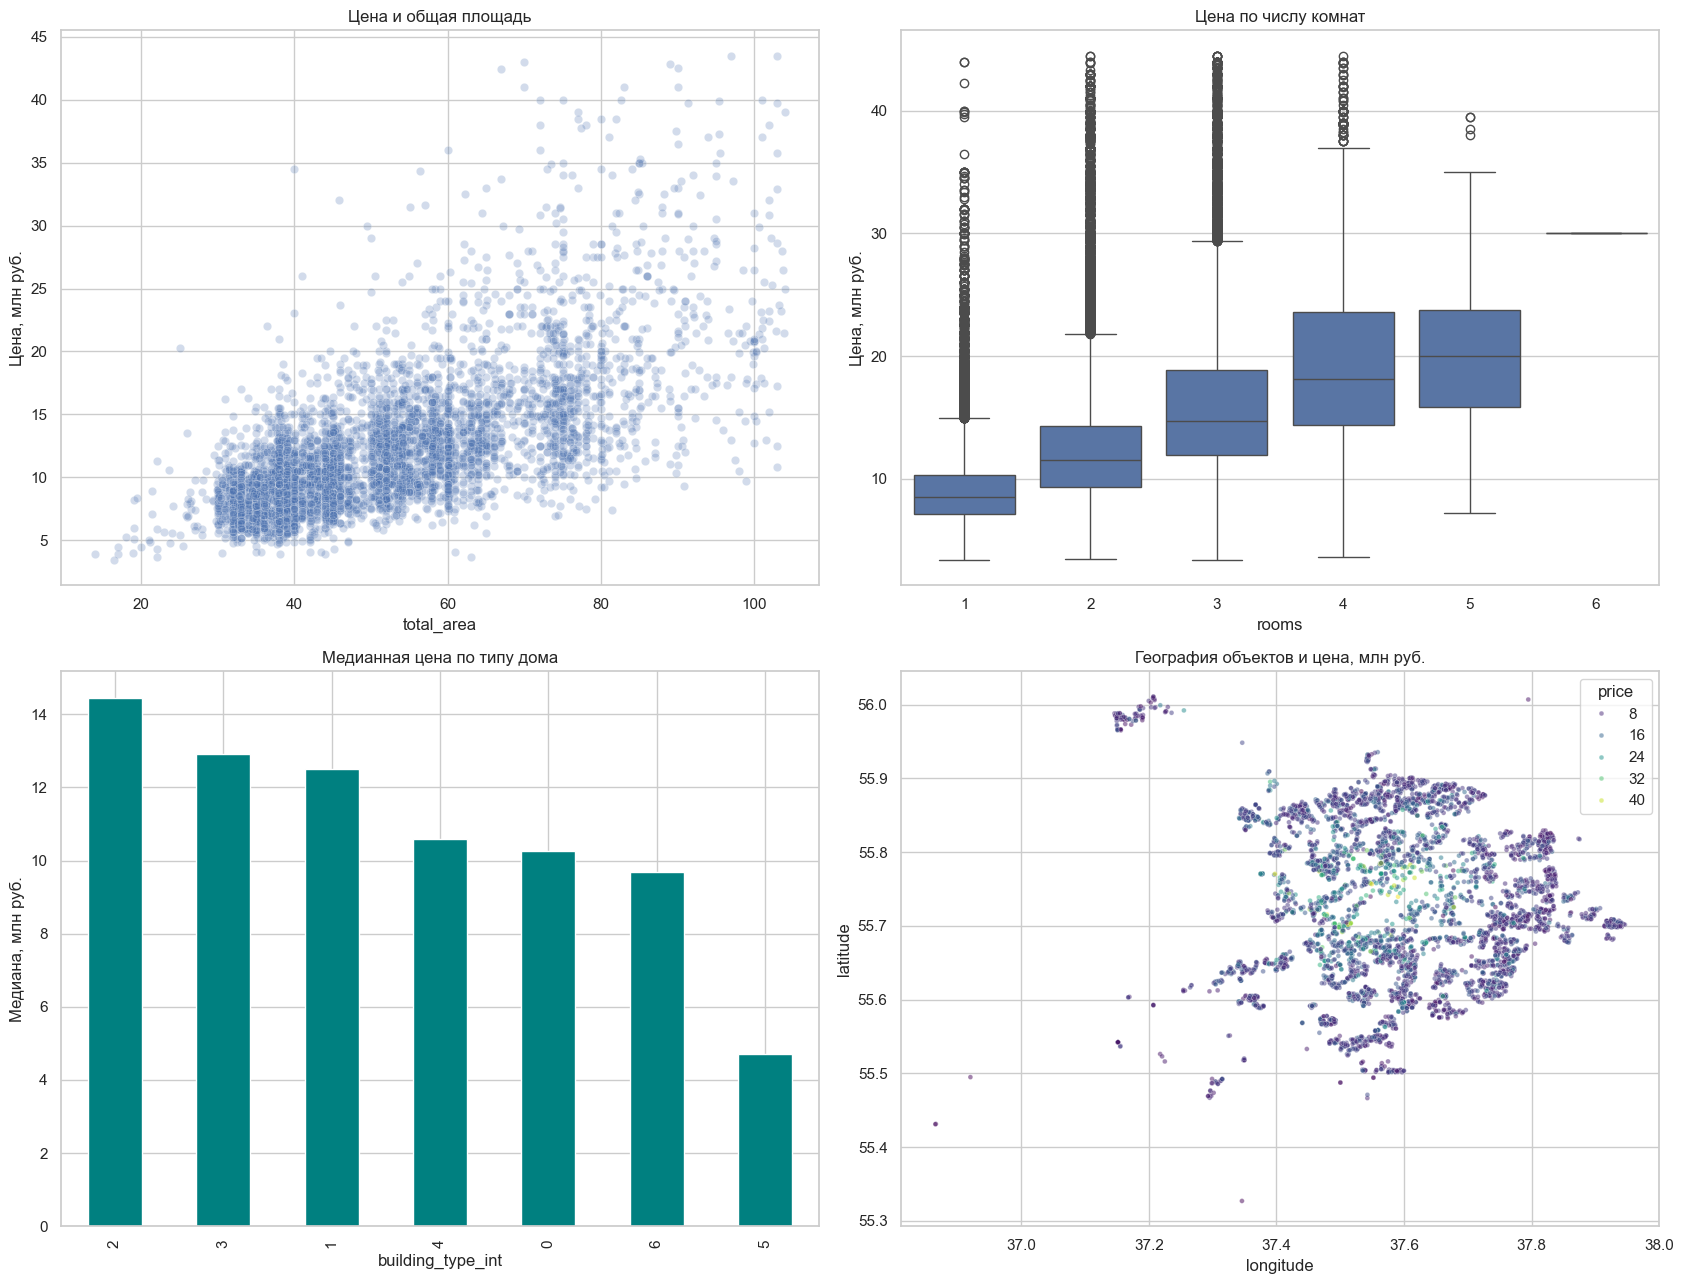

In [6]:
# Проверяем форму зависимости цены от площади, комнат, типа дома и географии.
plot_sample = df.sample(min(5_000, len(df)), random_state=RANDOM_STATE)
fig, axes = plt.subplots(2, 2, figsize=(17, 13))
sns.scatterplot(data=plot_sample, x="total_area", y=plot_sample["price"] / 1e6, alpha=0.25, ax=axes[0, 0])
axes[0, 0].set(title="Цена и общая площадь", ylabel="Цена, млн руб.")
sns.boxplot(data=df, x="rooms", y=df["price"] / 1e6, ax=axes[0, 1])
axes[0, 1].set(title="Цена по числу комнат", ylabel="Цена, млн руб.")
median_by_type = df.groupby("building_type_int")["price"].median().sort_values(ascending=False) / 1e6
median_by_type.plot.bar(ax=axes[1, 0], color="teal")
axes[1, 0].set(title="Медианная цена по типу дома", xlabel="building_type_int", ylabel="Медиана, млн руб.")
sns.scatterplot(data=plot_sample, x="longitude", y="latitude", hue=plot_sample["price"] / 1e6,
                palette="viridis", alpha=0.5, s=12, ax=axes[1, 1])
axes[1, 1].set_title("География объектов и цена, млн руб.")
plt.tight_layout()
fig.savefig(ARTIFACTS_DIR / "eda_target_relations.png", dpi=150, bbox_inches="tight")
plt.show()

In [7]:
# Числа для проверки выводов сохраняются как машиночитаемый артефакт.
eda_statistics = {
    "price_mean": float(df["price"].mean()),
    "price_median": float(df["price"].median()),
    "price_skew": float(df["price"].skew()),
    "total_area_pearson": float(df["total_area"].corr(df["price"])),
    "living_area_pearson": float(df["living_area"].corr(df["price"])),
    "rooms_pearson": float(df["rooms"].corr(df["price"])),
    "building_type_pearson": float(df["building_type_int"].corr(df["price"])),
}
save_json(eda_statistics, ARTIFACTS_DIR / "eda_statistics.json")
print(json.dumps(eda_statistics, ensure_ascii=False, indent=2))

{
  "price_mean": 12478133.62248128,
  "price_median": 11000000.0,
  "price_skew": 1.8172368164762396,
  "total_area_pearson": 0.6769457773314858,
  "living_area_pearson": 0.5951416632998375,
  "rooms_pearson": 0.5105661725250096,
  "building_type_pearson": -0.2787479077453978
}


### 2.4. Ключевые выводы EDA

1. **Пропусков и дублей `id` в очищенной выборке нет.** Все 123 525 строк можно использовать;
   булевы признаки дополнительно приведены к `0/1`, а идентификаторы исключены из обучения.
2. **Цена заметно правоскошенная:** среднее около 12,48 млн руб. выше медианы 11,0 млн руб..
   После очистки диапазон составляет 3,39–44,5 млн руб.. Для RF логарифмирование таргета не обязательно,
   но важно контролировать RMSE, чувствительный к редким дорогим объектам.
3. **Площадь — главный линейный сигнал:** корреляция `total_area` с ценой ≈ 0,677,
   `living_area` ≈ 0,595, `rooms` ≈ 0,511. Отношения площадей и нелинейные взаимодействия
   потенциально полезны, поэтому далее применяются полиномы и `autofeat`.
4. **Часть зависимостей нелинейна и категориальна.** Медианная цена различается по типам домов;
   координаты слабо описываются простой линейной корреляцией, но география может действовать через
   локальные сочетания. Это обосновывает one-hot для типа дома, биннинг координат и нелинейную RF.
5. **Признаки площадей связаны между собой.** Полный набор сгенерированных признаков может содержать
   избыточность, поэтому после генерации необходим отдельный этап forward/backward-отбора.

In [8]:
# Те же выводы сохраняем в Markdown и логируем вместе с ноутбуком и графиками.
eda_conclusions = '''# Выводы EDA

1. В очищенной выборке 123 525 строк, нет пропусков и дублей id. Идентификаторы исключены из признаков.
2. Цена правоскошенная: среднее ≈ 12,48 млн руб., медиана = 11,0 млн руб., диапазон 3,39–44,5 млн руб..
3. Наиболее сильная линейная связь с ценой у total_area (r ≈ 0,677), living_area (r ≈ 0,595) и rooms (r ≈ 0,511).
4. Тип дома учитывается как категория; географические и площадные зависимости могут быть нелинейными.
5. Для модели полезны полиномиальные, дискретизированные и автоматические признаки, после которых нужен отбор избыточных.
'''
(ARTIFACTS_DIR / "eda_conclusions.md").write_text(eda_conclusions, encoding="utf-8")

with mlflow.start_run(run_name="stage2_eda") as eda_run:
    mlflow.set_tags({"stage": "2", "analysis": "EDA"})
    mlflow.log_params(quality_summary)
    mlflow.log_metrics({"price_skew": eda_statistics["price_skew"], "price_mean": eda_statistics["price_mean"],
                        "price_median": eda_statistics["price_median"]})
    for filename in ["eda_quality.json", "eda_statistics.json", "eda_conclusions.md",
                     "eda_distributions.png", "eda_correlations.png", "eda_target_relations.png"]:
        mlflow.log_artifact(str(ARTIFACTS_DIR / filename), artifact_path="eda")
    mlflow.log_artifact(str(NOTEBOOK_PATH), artifact_path="code")
    mlflow.log_artifact(str(PROJECT_ROOT / "model_improvement" / "utils.py"), artifact_path="code")
    log_environment()
    print("EDA run id:", eda_run.info.run_id)

EDA run id: 029e4f9b156248b0b35e95a327779862


## Этап 3. Генерация признаков и обучение модели

### 3.1. Ручные и автоматические преобразования

- `PolynomialFeatures(degree=2)` создаёт квадраты и взаимодействия трёх площадей.
- `KBinsDiscretizer` переводит координаты, год, этаж и этажность в пять квантильных интервалов.
- `OneHotEncoder` кодирует тип дома; остальные исходные признаки сохраняются.
- `AutoFeatRegressor` автоматически строит безопасные преобразования `1/x`, `log(x)`, `sqrt(x)`, `x²`
  по девяти положительным числовым признакам и отбирает их по train.

Две ветки объединены `FeatureUnion`, а вместе с RF образуют единый `sklearn.Pipeline`.
Новые признаки вычисляются без `id`, `building_id` и `price`, поэтому утечки таргета нет.

In [9]:
# Списки колонок фиксируются явно: это упрощает проверку и воспроизводимость.
feature_cols = list(X_train.columns)
poly_cols = ["total_area", "living_area", "kitchen_area"]
bin_cols = ["latitude", "longitude", "build_year", "floor", "floors_total"]
auto_cols = ["floor", "kitchen_area", "living_area", "rooms", "total_area",
             "build_year", "ceiling_height", "flats_count", "floors_total"]
passthrough_cols = [c for c in feature_cols if c not in CATEGORICAL_COLS + poly_cols]


def make_feature_union():
    # Ручная ветка: все преобразования собраны в ColumnTransformer.
    manual = ColumnTransformer([
        ("numeric", "passthrough", passthrough_cols),
        ("polynomial", PolynomialFeatures(degree=2, include_bias=False), poly_cols),
        ("quantile_bins", KBinsDiscretizer(n_bins=5, encode="onehot-dense", strategy="quantile"), bin_cols),
        ("building_type", OneHotEncoder(handle_unknown="ignore", sparse_output=False), CATEGORICAL_COLS),
    ], sparse_threshold=0, verbose_feature_names_out=False).set_output(transform="pandas")

    # Автоматическая ветка использует только строго положительные поля, чтобы не делить на ноль.
    automatic = Pipeline([
        ("select", ColumnTransformer([("auto", "passthrough", auto_cols)],
                                     verbose_feature_names_out=False).set_output(transform="pandas")),
        ("autofeat", AutoFeatRegressor(
            feateng_steps=1, featsel_runs=3, max_gb=0.5,
            transformations=("1/", "log", "sqrt", "^2"), n_jobs=1, verbose=0,
        )),
    ])
    return FeatureUnion([("manual", manual), ("autofeat", automatic)])


feature_union = make_feature_union()
print("Ручные признаки:", poly_cols + bin_cols + CATEGORICAL_COLS + passthrough_cols)
print("Признаки для autofeat:", auto_cols)

Ручные признаки: ['total_area', 'living_area', 'kitchen_area', 'latitude', 'longitude', 'build_year', 'floor', 'floors_total', 'building_type_int', 'floor', 'rooms', 'is_apartment', 'studio', 'build_year', 'latitude', 'longitude', 'ceiling_height', 'flats_count', 'floors_total', 'has_elevator']
Признаки для autofeat: ['floor', 'kitchen_area', 'living_area', 'rooms', 'total_area', 'build_year', 'ceiling_height', 'flats_count', 'floors_total']


In [10]:
# Сначала обучаем преобразования только на train, затем применяем их к test.
feature_fit_started = time.perf_counter()
X_train_transformed = feature_union.fit_transform(X_train, y_train)
X_test_transformed = feature_union.transform(X_test)
feature_fit_seconds = time.perf_counter() - feature_fit_started

manual_transformer = feature_union.transformer_list[0][1]
auto_transformer = feature_union.transformer_list[1][1].named_steps["autofeat"]
feature_names = ([f"manual__{name}" for name in manual_transformer.get_feature_names_out()]
                 + [f"autofeat__{name}" for name in auto_transformer.all_columns_])
assert X_train_transformed.shape[1] == len(feature_names)
assert np.isfinite(X_train_transformed).all() and np.isfinite(X_test_transformed).all()

# RF сохраняет исходные параметры baseline: изменяется только набор признаков.
stage3_estimator = RandomForestRegressor(
    n_estimators=N_ESTIMATORS, max_depth=12, random_state=RANDOM_STATE, n_jobs=-1,
)
model_fit_started = time.perf_counter()
stage3_estimator.fit(X_train_transformed, y_train)
model_fit_seconds = time.perf_counter() - model_fit_started

prediction_started = time.perf_counter()
stage3_predictions = stage3_estimator.predict(X_test_transformed)
stage3_predict_seconds = time.perf_counter() - prediction_started
stage3_metrics = regression_metrics(y_test, stage3_predictions)
stage3_pipeline = Pipeline([("features", feature_union), ("model", stage3_estimator)])

print(f"До: {X_train.shape[1]} признаков; после: {X_train_transformed.shape[1]}")
print("Новые признаки autofeat:", auto_transformer.new_feat_cols_)
print("Метрики:", json.dumps(stage3_metrics, indent=2))
print(f"Fit: {feature_fit_seconds + model_fit_seconds:.2f} c; predict: {stage3_predict_seconds:.3f} c")

До: 15 признаков; после: 68
Новые признаки autofeat: ['1/floor', '1/flats_count', '1/kitchen_area', 'flats_count**2', '1/floors_total', 'kitchen_area**2', 'log(flats_count)']
Метрики: {
  "mae": 2006022.3072897573,
  "rmse": 2719988.296795131,
  "r2": 0.7751441899723612
}
Fit: 102.27 c; predict: 0.216 c


,total_area^2,total_area living_area,total_area kitchen_area,living_area^2,living_area kitchen_area,kitchen_area^2
55440,3025.000000,1683.000021,489.499979,936.360023,272.339992,79.209993
70523,1225.000000,682.500000,336.000013,380.250000,187.200007,92.160007
62259,1944.809865,1190.699959,264.599991,729.000000,162.000000,36.000000
103472,8299.209722,5174.479844,774.349987,3226.239913,482.799994,72.250000
99139,3600.000000,2040.000000,840.000000,1156.000000,476.000000,196.000000


,1/kitchen_area,flats_count**2,1/floors_total,kitchen_area**2,log(flats_count)
0,0.112360,16384.0,0.058824,79.209993,4.852030
1,0.104167,11025.0,0.062500,92.160007,4.653960
2,0.166667,230400.0,0.100000,36.000000,6.173786
3,0.117647,2116.0,0.111111,72.250000,3.828641
4,0.071429,36864.0,0.040000,196.000000,5.257495


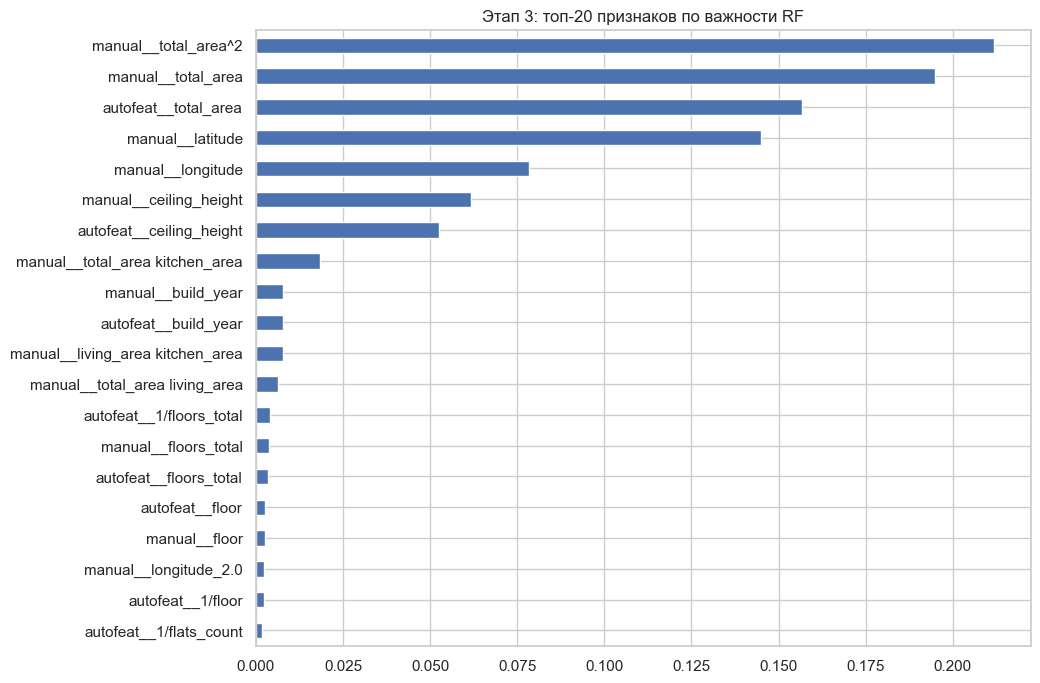

In [11]:
# Примеры сгенерированных признаков и важности для анализа результата.
manual_preview = manual_transformer.transform(X_train.head(5))
display(manual_preview.filter(regex="\^2| "))
display(pd.DataFrame(X_train_transformed[:5, -len(auto_transformer.all_columns_):],
                     columns=auto_transformer.all_columns_).iloc[:, -min(5, len(auto_transformer.all_columns_)):])

pd.DataFrame({"feature": feature_names}).to_csv(ARTIFACTS_DIR / "stage3_feature_names.csv", index=False)
importance3 = pd.Series(stage3_estimator.feature_importances_, index=feature_names).sort_values(ascending=False)
importance3.to_csv(ARTIFACTS_DIR / "stage3_feature_importance.csv", header=["importance"])
fig, ax = plt.subplots(figsize=(10, 8))
importance3.head(20).sort_values().plot.barh(ax=ax)
ax.set_title("Этап 3: топ-20 признаков по важности RF")
fig.savefig(ARTIFACTS_DIR / "stage3_feature_importance.png", dpi=150, bbox_inches="tight")
plt.show()

In [12]:
# Логируем параметры, скорость, метрики, код, графики и полный Pipeline в Model Registry.
input_example = X_train.head(3)
signature3 = infer_signature(input_example, stage3_pipeline.predict(input_example))
with mlflow.start_run(run_name="stage3_feature_generation") as run3:
    mlflow.set_tags({"stage": "3", "feature_engineering": "polynomial_bins_autofeat"})
    mlflow.log_params({"n_estimators": N_ESTIMATORS, "max_depth": 12, "polynomial_degree": 2,
                       "bins": 5, "autofeat_steps": 1, "autofeat_featsel_runs": 3})
    mlflow.log_params({"input_features": X_train.shape[1], "generated_features": X_train_transformed.shape[1],
                       "autofeat_new_features": len(auto_transformer.new_feat_cols_)})
    mlflow.log_metrics(stage3_metrics)
    mlflow.log_metrics({"fit_seconds": feature_fit_seconds + model_fit_seconds,
                        "predict_seconds": stage3_predict_seconds})
    for filename in ["stage3_feature_names.csv", "stage3_feature_importance.csv", "stage3_feature_importance.png"]:
        mlflow.log_artifact(str(ARTIFACTS_DIR / filename), artifact_path="features")
    mlflow.log_artifact(str(NOTEBOOK_PATH), artifact_path="code")
    log_environment()
    mlflow.sklearn.log_model(stage3_pipeline, artifact_path="model", signature=signature3,
                             input_example=input_example, registered_model_name=MODEL_NAME)
    print("Stage 3 run id:", run3.info.run_id)

/Users/natasa/Documents/Магистратура/MlOps_baseline/.venv/lib/python3.11/site-packages/mlflow/types/utils.py:393: UserWarning: Hint: Inferred schema contains integer column(s). Integer columns in Python cannot represent missing values. If your input data contains missing values at inference time, it will be encoded as floats and will cause a schema enforcement error. The best way to avoid this problem is to infer the model schema based on a realistic data sample (training dataset) that includes missing values. Alternatively, you can declare integer columns as doubles (float64) whenever these columns may have missing values. See `Handling Integers With Missing Values <https://www.mlflow.org/docs/latest/models.html#handling-integers-with-missing-values>`_ for more details.
  warnings.warn(


Stage 3 run id: 264b917fae2e49e3b95625a3393ab3a3


Registered model 'real_estate_price_model' already exists. Creating a new version of this model...
Created version '2' of model 'real_estate_price_model'.


## Этап 4. Отбор признаков

Сначала RF оставляет 25 наиболее информативных кандидатов — это ограничивает вычислительную стоимость.
Затем на случайной train-подвыборке независимо запускаются два метода `mlxtend`:

- **Forward Selection** последовательно добавляет признаки;
- **Backward Selection** последовательно удаляет признаки.

Оба используют 2-fold CV и RMSE. В финальный список сначала входит пересечение методов, затем —
наиболее важные признаки из их объединения до заданного размера. Test в отборе не участвует.

In [13]:
# Ограничиваем кандидатов важностью модели этапа 3; сама важность получена только на train.
candidate_positions = np.argsort(stage3_estimator.feature_importances_)[-CANDIDATE_COUNT:]
candidate_names = [feature_names[i] for i in candidate_positions]
selection_rng = np.random.default_rng(RANDOM_STATE)
selection_indices = selection_rng.choice(
    len(X_train), size=min(SELECTION_SAMPLE_SIZE, len(X_train)), replace=False,
)
X_selection = X_train_transformed[selection_indices][:, candidate_positions]
y_selection = y_train.iloc[selection_indices]


def selection_estimator():
    # Небольшой RF делает последовательный поиск воспроизводимым и не слишком дорогим.
    return RandomForestRegressor(n_estimators=20, max_depth=10, random_state=RANDOM_STATE, n_jobs=1)


sfs_forward = SequentialFeatureSelector(
    selection_estimator(), k_features=SELECTED_COUNT, forward=True, floating=False,
    scoring="neg_root_mean_squared_error", cv=2, n_jobs=-1,
)
sfs_backward = SequentialFeatureSelector(
    selection_estimator(), k_features=SELECTED_COUNT, forward=False, floating=False,
    scoring="neg_root_mean_squared_error", cv=2, n_jobs=-1,
)
print("Forward selection...")
sfs_forward.fit(X_selection, y_selection)
print("Backward selection...")
sfs_backward.fit(X_selection, y_selection)

forward_names = [candidate_names[i] for i in sfs_forward.k_feature_idx_]
backward_names = [candidate_names[i] for i in sfs_backward.k_feature_idx_]
print("Forward:", forward_names)
print("Backward:", backward_names)

Forward selection...


Backward selection...


Forward: ['autofeat__1/floor', 'manual__longitude_2.0', 'manual__floor', 'autofeat__floors_total', 'manual__total_area living_area', 'autofeat__build_year', 'manual__longitude', 'manual__latitude', 'autofeat__total_area', 'manual__total_area^2']
Backward: ['manual__flats_count', 'autofeat__1/floor', 'manual__floor', 'autofeat__1/floors_total', 'autofeat__build_year', 'autofeat__ceiling_height', 'manual__longitude', 'manual__latitude', 'autofeat__total_area', 'manual__total_area^2']


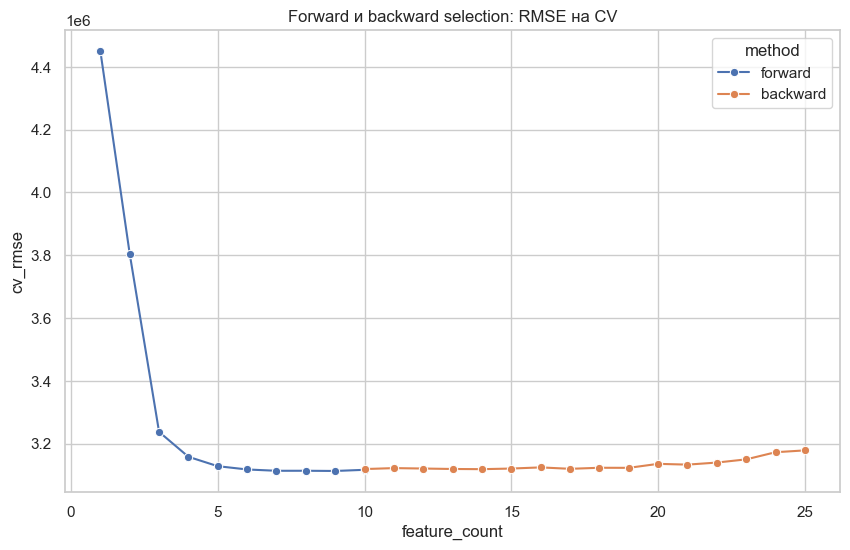

Пересечение: ['autofeat__1/floor', 'manual__floor', 'autofeat__build_year', 'manual__longitude', 'manual__latitude', 'autofeat__total_area', 'manual__total_area^2']
Итоговые признаки: ['autofeat__1/floor', 'manual__floor', 'autofeat__build_year', 'manual__longitude', 'manual__latitude', 'autofeat__total_area', 'manual__total_area^2', 'autofeat__ceiling_height', 'manual__total_area living_area', 'autofeat__1/floors_total']


In [14]:
# Сравниваем траектории качества и формируем итоговый список без обращения к test.
selection_history = []
for method, selector in [("forward", sfs_forward), ("backward", sfs_backward)]:
    for subset in selector.subsets_.values():
        selection_history.append({"method": method, "feature_count": len(subset["feature_idx"]),
                                  "cv_rmse": -subset["avg_score"],
                                  "features": ", ".join(candidate_names[i] for i in subset["feature_idx"])})
selection_history_df = pd.DataFrame(selection_history)
selection_history_df.to_csv(ARTIFACTS_DIR / "stage4_selection_history.csv", index=False)

fig, ax = plt.subplots(figsize=(10, 6))
sns.lineplot(data=selection_history_df, x="feature_count", y="cv_rmse", hue="method", marker="o", ax=ax)
ax.set_title("Forward и backward selection: RMSE на CV")
fig.savefig(ARTIFACTS_DIR / "stage4_selection_cv.png", dpi=150, bbox_inches="tight")
plt.show()

common = [name for name in forward_names if name in backward_names]
union = list(dict.fromkeys(forward_names + backward_names))
remaining = sorted((name for name in union if name not in common),
                   key=lambda name: importance3[name], reverse=True)
selected_names = (common + remaining)[:SELECTED_COUNT]
selected_positions = [feature_names.index(name) for name in selected_names]
print("Пересечение:", common)
print("Итоговые признаки:", selected_names)

for filename, names in [("stage4_forward_features.txt", forward_names),
                        ("stage4_backward_features.txt", backward_names),
                        ("stage4_selected_features.txt", selected_names)]:
    (ARTIFACTS_DIR / filename).write_text("\n".join(names), encoding="utf-8")

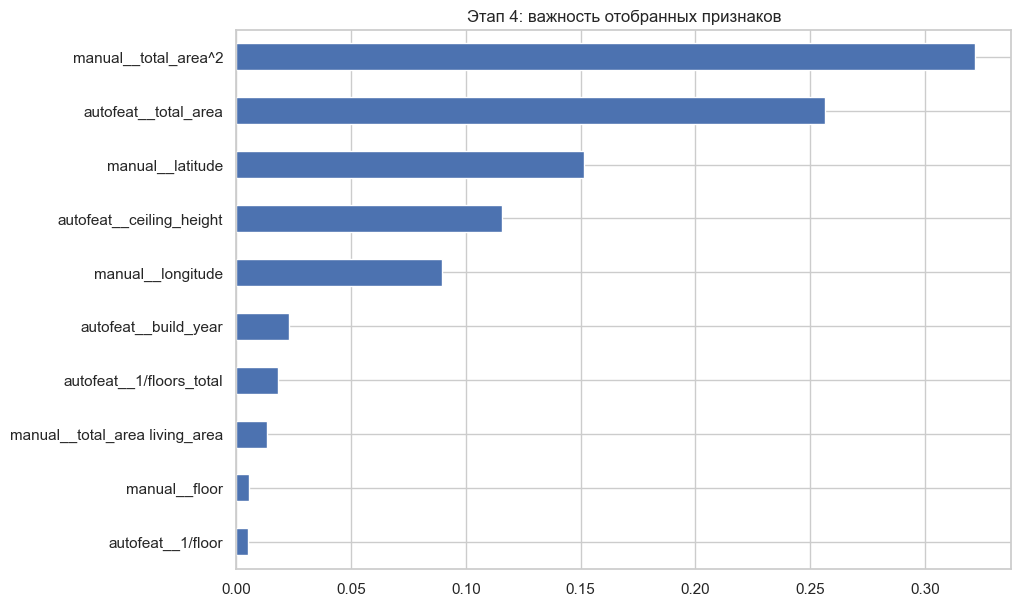

{
  "mae": 2005998.5308387585,
  "rmse": 2729623.6625194876,
  "r2": 0.7735482967663978
}


In [15]:
# Обучаем RF на полном train только с отобранными признаками; параметры пока прежние.
selector = ColumnTransformer([("selected", "passthrough", selected_positions)])
selector.fit(X_train_transformed)
stage4_estimator = RandomForestRegressor(
    n_estimators=N_ESTIMATORS, max_depth=12, random_state=RANDOM_STATE, n_jobs=-1,
)
fit_started = time.perf_counter()
stage4_estimator.fit(X_train_transformed[:, selected_positions], y_train)
stage4_fit_seconds = time.perf_counter() - fit_started
predict_started = time.perf_counter()
stage4_predictions = stage4_estimator.predict(X_test_transformed[:, selected_positions])
stage4_predict_seconds = time.perf_counter() - predict_started
stage4_metrics = regression_metrics(y_test, stage4_predictions)
stage4_pipeline = Pipeline([("features", feature_union), ("selector", selector), ("model", stage4_estimator)])

importance4 = pd.Series(stage4_estimator.feature_importances_, index=selected_names).sort_values(ascending=False)
importance4.to_csv(ARTIFACTS_DIR / "stage4_feature_importance.csv", header=["importance"])
fig, ax = plt.subplots(figsize=(10, 7))
importance4.sort_values().plot.barh(ax=ax)
ax.set_title("Этап 4: важность отобранных признаков")
fig.savefig(ARTIFACTS_DIR / "stage4_feature_importance.png", dpi=150, bbox_inches="tight")
plt.show()
print(json.dumps(stage4_metrics, indent=2))

In [16]:
# Регистрируем третью версию модели и все доказательства процесса отбора.
signature4 = infer_signature(input_example, stage4_pipeline.predict(input_example))
with mlflow.start_run(run_name="stage4_feature_selection") as run4:
    mlflow.set_tags({"stage": "4", "selection_methods": "forward_backward_mlxtend"})
    mlflow.log_params({"n_estimators": N_ESTIMATORS, "max_depth": 12,
                       "candidate_count": len(candidate_names), "selected_count": len(selected_names),
                       "selection_sample_size": len(X_selection), "selection_cv": 2})
    mlflow.log_metrics(stage4_metrics)
    mlflow.log_metrics({"fit_seconds": stage4_fit_seconds, "predict_seconds": stage4_predict_seconds,
                        "forward_best_cv_rmse": -sfs_forward.k_score_,
                        "backward_best_cv_rmse": -sfs_backward.k_score_})
    for filename in ["stage4_selection_history.csv", "stage4_selection_cv.png",
                     "stage4_forward_features.txt", "stage4_backward_features.txt",
                     "stage4_selected_features.txt", "stage4_feature_importance.csv",
                     "stage4_feature_importance.png"]:
        mlflow.log_artifact(str(ARTIFACTS_DIR / filename), artifact_path="selection")
    mlflow.log_artifact(str(NOTEBOOK_PATH), artifact_path="code")
    log_environment()
    mlflow.sklearn.log_model(stage4_pipeline, artifact_path="model", signature=signature4,
                             input_example=input_example, registered_model_name=MODEL_NAME)
    print("Stage 4 run id:", run4.info.run_id)

/Users/natasa/Documents/Магистратура/MlOps_baseline/.venv/lib/python3.11/site-packages/mlflow/types/utils.py:393: UserWarning: Hint: Inferred schema contains integer column(s). Integer columns in Python cannot represent missing values. If your input data contains missing values at inference time, it will be encoded as floats and will cause a schema enforcement error. The best way to avoid this problem is to infer the model schema based on a realistic data sample (training dataset) that includes missing values. Alternatively, you can declare integer columns as doubles (float64) whenever these columns may have missing values. See `Handling Integers With Missing Values <https://www.mlflow.org/docs/latest/models.html#handling-integers-with-missing-values>`_ for more details.
  warnings.warn(


/Users/natasa/Documents/Магистратура/MlOps_baseline/.venv/lib/python3.11/site-packages/_distutils_hack/__init__.py:15: UserWarning: Distutils was imported before Setuptools, but importing Setuptools also replaces the `distutils` module in `sys.modules`. This may lead to undesirable behaviors or errors. To avoid these issues, avoid using distutils directly, ensure that setuptools is installed in the traditional way (e.g. not an editable install), and/or make sure that setuptools is always imported before distutils.
  warnings.warn(
/Users/natasa/Documents/Магистратура/MlOps_baseline/.venv/lib/python3.11/site-packages/_distutils_hack/__init__.py:30: UserWarning: Setuptools is replacing distutils. Support for replacing an already imported distutils is deprecated. In the future, this condition will fail. Register concerns at https://github.com/pypa/setuptools/issues/new?template=distutils-deprecation.yml
  warnings.warn(


Stage 4 run id: 555115550be04726a4e6d2e6deaff0d9


Registered model 'real_estate_price_model' already exists. Creating a new version of this model...
Created version '3' of model 'real_estate_price_model'.


## Этап 5. Подбор гиперпараметров и финальная модель

Используются два независимых метода:

1. **Optuna TPE** с `MLflowCallback`: каждая попытка создаёт вложенный MLflow run.
2. **RandomizedSearchCV**: параметры и средний RMSE каждой комбинации логируются отдельно.

Оба метода сравниваются по одинаковой 3-fold CV на одной train-подвыборке. Лучший набор затем
обучается на полном train и один раз оценивается на test. Настраиваются глубина, число деревьев,
минимальное число объектов в листе и доля признаков при разбиении.

[I 2026-11-14 18:22:49,387] A new study created in memory with name: no-name-cb3a3af2-52b8-47ba-bafe-c96721ec1d39


/var/folders/ry/b59stfbx7239z00g9xmlvshh0000gp/T/ipykernel_25062/4078971938.py:27: ExperimentalWarning: MLflowCallback is experimental (supported from v1.4.0). The interface can change in the future.
  callback = MLflowCallback(


[I 2026-11-14 18:22:55,112] Trial 0 finished with value: 2930999.715400008 and parameters: {'n_estimators': 100, 'max_depth': 24, 'min_samples_leaf': 4, 'max_features': 'sqrt'}. Best is trial 0 with value: 2930999.715400008.


[I 2026-11-14 18:23:02,617] Trial 1 finished with value: 2898826.33001652 and parameters: {'n_estimators': 50, 'max_depth': 24, 'min_samples_leaf': 4, 'max_features': 1.0}. Best is trial 1 with value: 2898826.33001652.


[I 2026-11-14 18:23:28,733] Trial 2 finished with value: 2915036.5937468 and parameters: {'n_estimators': 200, 'max_depth': 12, 'min_samples_leaf': 1, 'max_features': 1.0}. Best is trial 1 with value: 2898826.33001652.


[I 2026-11-14 18:23:40,987] Trial 3 finished with value: 2916054.2566000577 and parameters: {'n_estimators': 100, 'max_depth': 12, 'min_samples_leaf': 4, 'max_features': 1.0}. Best is trial 1 with value: 2898826.33001652.


... (13 outputs left out)

[I 2026-11-14 18:28:47,095] Trial 17 finished with value: 2909063.9140986153 and parameters: {'n_estimators': 200, 'max_depth': 12, 'min_samples_leaf': 3, 'max_features': 1.0}. Best is trial 14 with value: 2875744.9607973876.


[I 2026-11-14 18:28:55,443] Trial 18 finished with value: 2938428.9815506167 and parameters: {'n_estimators': 150, 'max_depth': 20, 'min_samples_leaf': 5, 'max_features': 'sqrt'}. Best is trial 14 with value: 2875744.9607973876.


[I 2026-11-14 18:29:20,414] Trial 19 finished with value: 2871658.7021662034 and parameters: {'n_estimators': 200, 'max_depth': 20, 'min_samples_leaf': 2, 'max_features': 0.7}. Best is trial 19 with value: 2871658.7021662034.


Optuna parent run id: 336600a89327465e83c894fcd32c3735


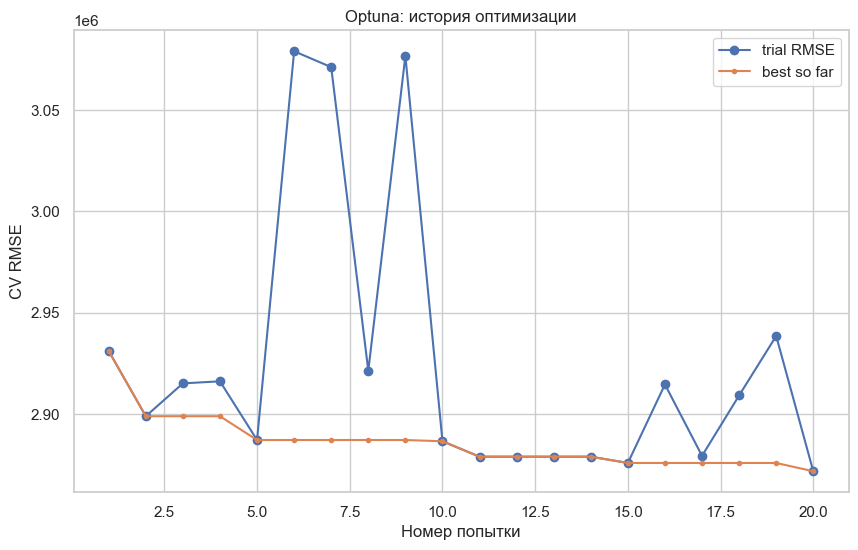

Optuna best: {'n_estimators': 200, 'max_depth': 20, 'min_samples_leaf': 2, 'max_features': 0.7} RMSE: 2871658.7021662034


In [17]:
# Одна подвыборка и один объект CV обеспечивают честное сравнение Optuna и Random Search.
search_rng = np.random.default_rng(RANDOM_STATE)
search_indices = search_rng.choice(len(X_train), size=min(SEARCH_SAMPLE_SIZE, len(X_train)), replace=False)
X_search = X_train_transformed[search_indices][:, selected_positions]
y_search = y_train.iloc[search_indices]
cv = KFold(n_splits=3, shuffle=True, random_state=RANDOM_STATE)


def optuna_objective(trial):
    params = {
        "n_estimators": trial.suggest_int("n_estimators", 50, 200, step=50),
        "max_depth": trial.suggest_int("max_depth", 8, 24, step=4),
        "min_samples_leaf": trial.suggest_int("min_samples_leaf", 1, 5),
        "max_features": trial.suggest_categorical("max_features", ["sqrt", 0.7, 1.0]),
    }
    estimator = RandomForestRegressor(**params, random_state=RANDOM_STATE, n_jobs=-1)
    scores = cross_val_score(estimator, X_search, y_search, scoring="neg_root_mean_squared_error",
                             cv=cv, n_jobs=1)
    trial.set_user_attr("cv_rmse_std", float(scores.std()))
    return float(-scores.mean())


study = optuna.create_study(direction="minimize", sampler=optuna.samplers.TPESampler(seed=RANDOM_STATE))
with mlflow.start_run(run_name="stage5_optuna_parent") as optuna_parent:
    mlflow.set_tags({"stage": "5", "optimization": "optuna_tpe"})
    mlflow.log_params({"n_trials": N_TRIALS, "search_rows": len(X_search), "cv_folds": 3})
    callback = MLflowCallback(
        tracking_uri=mlflow.get_tracking_uri(), metric_name="cv_rmse",
        create_experiment=False, mlflow_kwargs={"nested": True},
    )
    study.optimize(optuna_objective, n_trials=N_TRIALS, callbacks=[callback], show_progress_bar=False)
    mlflow.log_params({f"best_{key}": value for key, value in study.best_params.items()})
    mlflow.log_metric("best_cv_rmse", study.best_value)
    study.trials_dataframe().to_csv(ARTIFACTS_DIR / "stage5_optuna_trials.csv", index=False)
    log_environment()
    print("Optuna parent run id:", optuna_parent.info.run_id)

fig, ax = plt.subplots(figsize=(10, 6))
values = [trial.value for trial in study.trials if trial.value is not None]
ax.plot(range(1, len(values) + 1), values, marker="o", label="trial RMSE")
ax.plot(range(1, len(values) + 1), np.minimum.accumulate(values), marker=".", label="best so far")
ax.set(xlabel="Номер попытки", ylabel="CV RMSE", title="Optuna: история оптимизации")
ax.legend()
fig.savefig(ARTIFACTS_DIR / "stage5_optuna_history.png", dpi=150, bbox_inches="tight")
plt.show()
print("Optuna best:", study.best_params, "RMSE:", study.best_value)

In [18]:
# Второй метод: случайный поиск по тому же пространству и на той же train-подвыборке.
param_distributions = {
    "n_estimators": [50, 100, 150, 200],
    "max_depth": [8, 12, 16, 20, 24],
    "min_samples_leaf": [1, 2, 3, 4, 5],
    "max_features": ["sqrt", 0.7, 1.0],
}
random_search = RandomizedSearchCV(
    RandomForestRegressor(random_state=RANDOM_STATE, n_jobs=1),
    param_distributions=param_distributions, n_iter=N_ITER, scoring="neg_root_mean_squared_error",
    cv=cv, random_state=RANDOM_STATE, n_jobs=-1, return_train_score=False,
)
with mlflow.start_run(run_name="stage5_random_search_parent") as random_parent:
    mlflow.set_tags({"stage": "5", "optimization": "randomized_search_cv"})
    mlflow.log_params({"n_iter": N_ITER, "search_rows": len(X_search), "cv_folds": 3})
    random_search.fit(X_search, y_search)
    results = random_search.cv_results_
    for i, params in enumerate(results["params"]):
        with mlflow.start_run(run_name=f"random_search_trial_{i + 1}", nested=True):
            mlflow.log_params(params)
            mlflow.log_metrics({
                "cv_rmse": float(-results["mean_test_score"][i]),
                "cv_rmse_std": float(results["std_test_score"][i]),
                "rank": int(results["rank_test_score"][i]),
            })
    mlflow.log_params({f"best_{key}": value for key, value in random_search.best_params_.items()})
    mlflow.log_metric("best_cv_rmse", float(-random_search.best_score_))
    pd.DataFrame(results).drop(columns=["params"]).to_csv(ARTIFACTS_DIR / "stage5_random_search_results.csv", index=False)
    log_environment()
    print("Random Search parent run id:", random_parent.info.run_id)

random_rmse = float(-random_search.best_score_)
print("Random Search best:", random_search.best_params_, "RMSE:", random_rmse)

Random Search parent run id: 0ee140ac234d49e7aa9e19bfe56ac0d9
Random Search best: {'n_estimators': 150, 'min_samples_leaf': 2, 'max_features': 0.7, 'max_depth': 24} RMSE: 2876312.07244282


In [19]:
# Выбираем победителя строго по CV, а не по test — это предотвращает оптимистичное смещение.
tuning_comparison = {
    "optuna": {"cv_rmse": float(study.best_value), "params": study.best_params},
    "random_search": {"cv_rmse": random_rmse, "params": random_search.best_params_},
}
if study.best_value <= random_rmse:
    best_method = "optuna"
    best_params = dict(study.best_params)
else:
    best_method = "random_search"
    best_params = dict(random_search.best_params_)
tuning_comparison["selected_method"] = best_method
tuning_comparison["selected_params"] = best_params
save_json(tuning_comparison, ARTIFACTS_DIR / "stage5_tuning_comparison.json")
print("Выбран метод:", best_method)
print("Лучшие параметры:", best_params)

Выбран метод: optuna
Лучшие параметры: {'n_estimators': 200, 'max_depth': 20, 'min_samples_leaf': 2, 'max_features': 0.7}


,mae,rmse,r2,rmse_improvement_vs_baseline_pct,r2_gain_vs_baseline
stage,,,,,
1_baseline,2.003737e+06,2.721366e+06,0.774916,0.000000,0.000000
3_generated_features,2.006022e+06,2.719988e+06,0.775144,0.050617,0.000228
4_selected_features,2.005999e+06,2.729624e+06,0.773548,-0.303446,-0.001368
5_tuned_model,1.771244e+06,2.467799e+06,0.814907,9.317624,0.039991


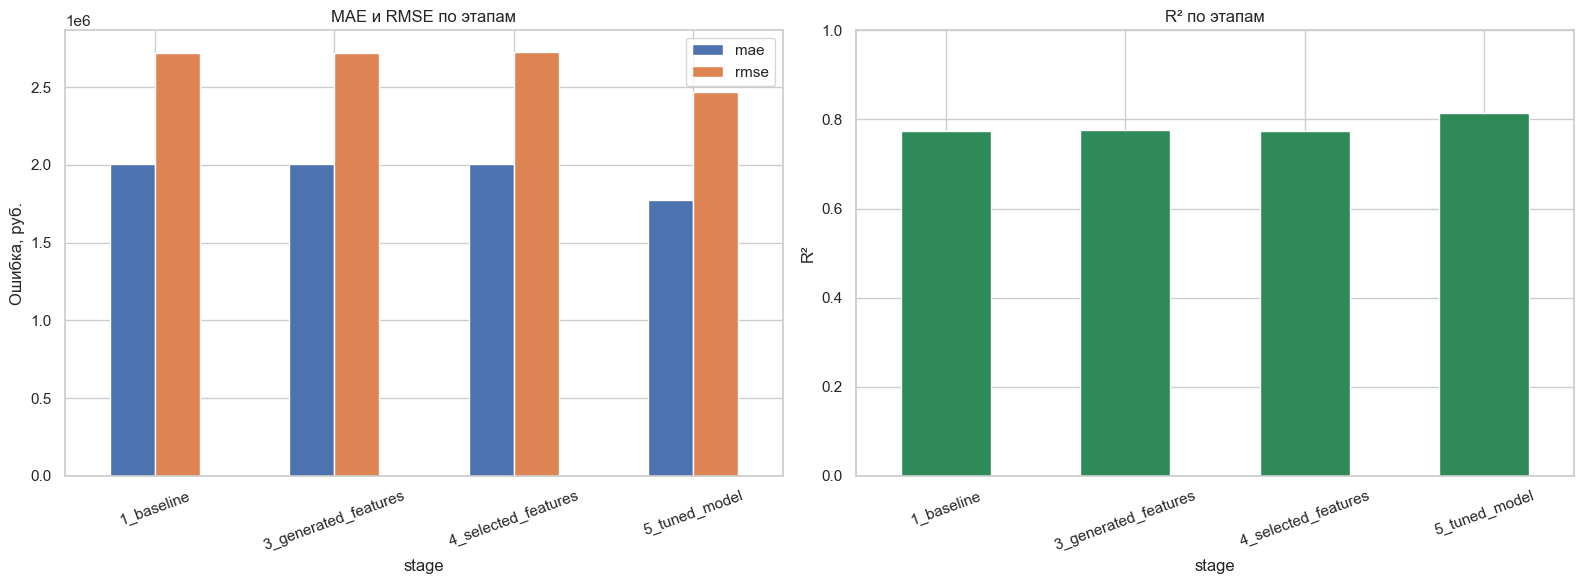

In [20]:
# Финальное обучение: полный train, отобранные признаки, лучшие гиперпараметры.
final_estimator = RandomForestRegressor(**best_params, random_state=RANDOM_STATE, n_jobs=-1)
fit_started = time.perf_counter()
final_estimator.fit(X_train_transformed[:, selected_positions], y_train)
final_fit_seconds = time.perf_counter() - fit_started
predict_started = time.perf_counter()
final_predictions = final_estimator.predict(X_test_transformed[:, selected_positions])
final_predict_seconds = time.perf_counter() - predict_started
final_metrics = regression_metrics(y_test, final_predictions)
final_pipeline = Pipeline([("features", feature_union), ("selector", selector), ("model", final_estimator)])

comparison = pd.DataFrame([
    {"stage": "1_baseline", **baseline_metrics},
    {"stage": "3_generated_features", **stage3_metrics},
    {"stage": "4_selected_features", **stage4_metrics},
    {"stage": "5_tuned_model", **final_metrics},
]).set_index("stage")
comparison["rmse_improvement_vs_baseline_pct"] = 100 * (baseline_metrics["rmse"] - comparison["rmse"]) / baseline_metrics["rmse"]
comparison["r2_gain_vs_baseline"] = comparison["r2"] - baseline_metrics["r2"]
display(comparison)
comparison.to_csv(ARTIFACTS_DIR / "final_model_comparison.csv")
save_json(comparison.reset_index().to_dict(orient="records"), ARTIFACTS_DIR / "final_model_comparison.json")

fig, axes = plt.subplots(1, 2, figsize=(16, 6))
comparison[["mae", "rmse"]].plot.bar(ax=axes[0])
axes[0].set(title="MAE и RMSE по этапам", ylabel="Ошибка, руб.")
axes[0].tick_params(axis="x", rotation=20)
comparison["r2"].plot.bar(ax=axes[1], color="seagreen")
axes[1].set(title="R² по этапам", ylabel="R²", ylim=(0, 1))
axes[1].tick_params(axis="x", rotation=20)
plt.tight_layout()
fig.savefig(ARTIFACTS_DIR / "final_metrics_comparison.png", dpi=150, bbox_inches="tight")
plt.show()

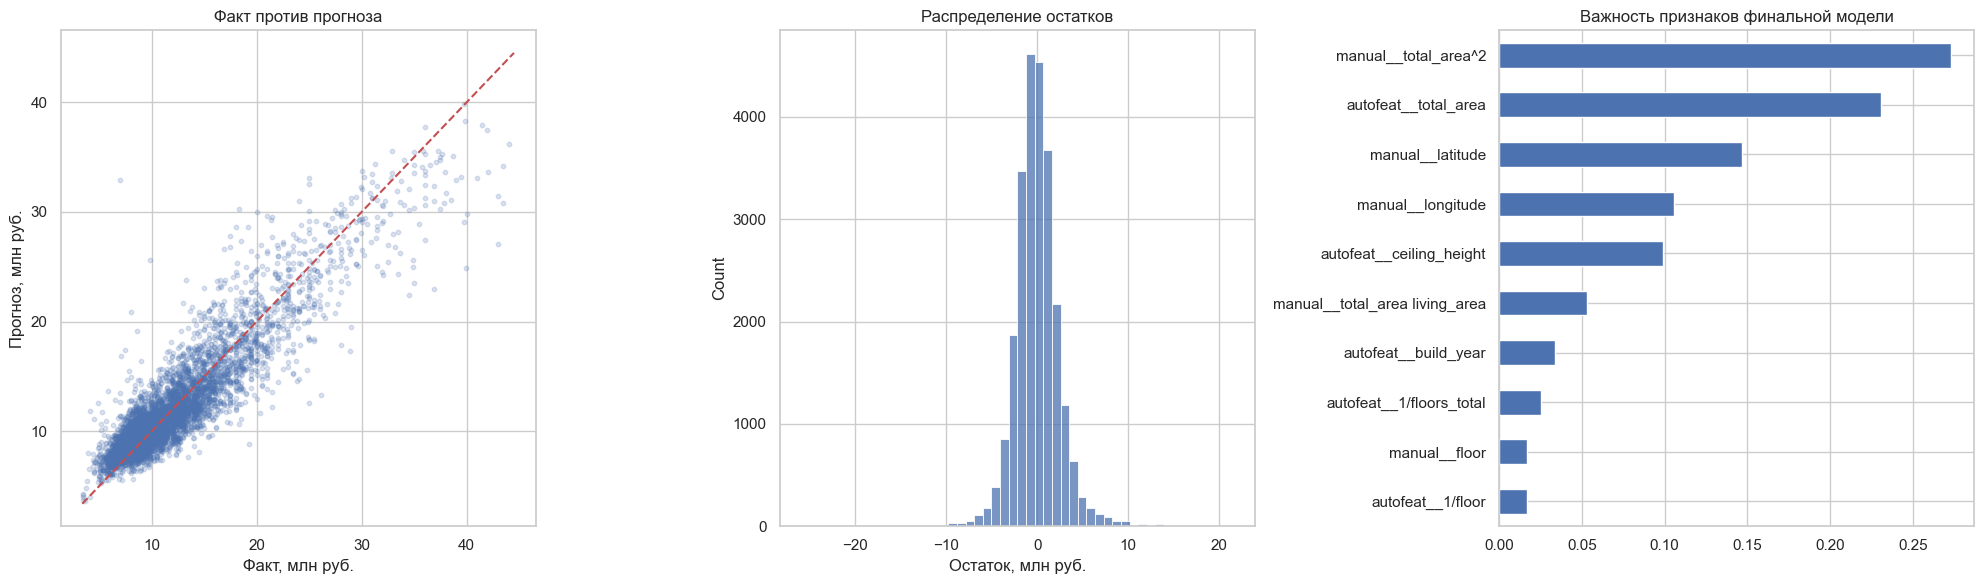

{
  "mae": 1771243.8319733054,
  "rmse": 2467799.136029549,
  "r2": 0.8149071431775303
}


In [21]:
# Диагностика финальных ошибок и важности признаков.
final_importance = pd.Series(final_estimator.feature_importances_, index=selected_names).sort_values(ascending=False)
final_importance.to_csv(ARTIFACTS_DIR / "final_feature_importance.csv", header=["importance"])
residuals = y_test.to_numpy() - final_predictions
residual_sample = np.random.default_rng(RANDOM_STATE).choice(len(y_test), size=min(5_000, len(y_test)), replace=False)

fig, axes = plt.subplots(1, 3, figsize=(20, 6))
axes[0].scatter(y_test.to_numpy()[residual_sample] / 1e6, final_predictions[residual_sample] / 1e6, alpha=0.2, s=10)
axes[0].plot([df["price"].min() / 1e6, df["price"].max() / 1e6],
             [df["price"].min() / 1e6, df["price"].max() / 1e6], "r--")
axes[0].set(xlabel="Факт, млн руб.", ylabel="Прогноз, млн руб.", title="Факт против прогноза")
sns.histplot(residuals / 1e6, bins=50, ax=axes[1])
axes[1].set(xlabel="Остаток, млн руб.", title="Распределение остатков")
final_importance.sort_values().plot.barh(ax=axes[2])
axes[2].set_title("Важность признаков финальной модели")
plt.tight_layout()
fig.savefig(ARTIFACTS_DIR / "final_diagnostics.png", dpi=150, bbox_inches="tight")
plt.show()
print(json.dumps(final_metrics, ensure_ascii=False, indent=2))

In [22]:
# Финальный run: полный Pipeline, сигнатура, метрики, параметры и все дополнительные артефакты.
final_signature = infer_signature(input_example, final_pipeline.predict(input_example))
with mlflow.start_run(run_name="stage5_final_model") as final_run:
    mlflow.set_tags({"stage": "5", "model_type": "final", "optimization_method": best_method})
    mlflow.log_params(best_params)
    mlflow.log_params({"selected_method": best_method, "selected_features_count": len(selected_names),
                       "train_rows": len(X_train), "test_rows": len(X_test)})
    mlflow.log_metrics(final_metrics)
    mlflow.log_metrics({"fit_seconds": final_fit_seconds, "predict_seconds": final_predict_seconds,
                        "best_cv_rmse": tuning_comparison[best_method]["cv_rmse"],
                        "rmse_improvement_pct": comparison.loc["5_tuned_model", "rmse_improvement_vs_baseline_pct"]})
    mlflow.log_artifact(str(ARTIFACTS_DIR / "stage5_optuna_trials.csv"), artifact_path="tuning")
    mlflow.log_artifact(str(ARTIFACTS_DIR / "stage5_optuna_history.png"), artifact_path="tuning")
    mlflow.log_artifact(str(ARTIFACTS_DIR / "stage5_random_search_results.csv"), artifact_path="tuning")
    mlflow.log_artifact(str(ARTIFACTS_DIR / "stage5_tuning_comparison.json"), artifact_path="tuning")
    mlflow.log_artifact(str(ARTIFACTS_DIR / "final_model_comparison.csv"), artifact_path="evaluation")
    mlflow.log_artifact(str(ARTIFACTS_DIR / "final_metrics_comparison.png"), artifact_path="evaluation")
    mlflow.log_artifact(str(ARTIFACTS_DIR / "final_diagnostics.png"), artifact_path="evaluation")
    mlflow.log_artifact(str(ARTIFACTS_DIR / "final_feature_importance.csv"), artifact_path="evaluation")
    mlflow.log_artifact(str(NOTEBOOK_PATH), artifact_path="code")
    log_environment()
    mlflow.sklearn.log_model(final_pipeline, artifact_path="model", signature=final_signature,
                             input_example=input_example, registered_model_name=MODEL_NAME)
    save_json({"run_id": final_run.info.run_id, "experiment_id": experiment.experiment_id,
               "model_name": MODEL_NAME, "metrics": final_metrics,
               "best_method": best_method, "best_params": best_params},
              ARTIFACTS_DIR / "final_run_info.json")
    print("Final run id:", final_run.info.run_id)

print("Готово: зарегистрированы baseline и три улучшенные версии модели.")

/Users/natasa/Documents/Магистратура/MlOps_baseline/.venv/lib/python3.11/site-packages/mlflow/types/utils.py:393: UserWarning: Hint: Inferred schema contains integer column(s). Integer columns in Python cannot represent missing values. If your input data contains missing values at inference time, it will be encoded as floats and will cause a schema enforcement error. The best way to avoid this problem is to infer the model schema based on a realistic data sample (training dataset) that includes missing values. Alternatively, you can declare integer columns as doubles (float64) whenever these columns may have missing values. See `Handling Integers With Missing Values <https://www.mlflow.org/docs/latest/models.html#handling-integers-with-missing-values>`_ for more details.
  warnings.warn(


/Users/natasa/Documents/Магистратура/MlOps_baseline/.venv/lib/python3.11/site-packages/_distutils_hack/__init__.py:15: UserWarning: Distutils was imported before Setuptools, but importing Setuptools also replaces the `distutils` module in `sys.modules`. This may lead to undesirable behaviors or errors. To avoid these issues, avoid using distutils directly, ensure that setuptools is installed in the traditional way (e.g. not an editable install), and/or make sure that setuptools is always imported before distutils.
  warnings.warn(
/Users/natasa/Documents/Магистратура/MlOps_baseline/.venv/lib/python3.11/site-packages/_distutils_hack/__init__.py:30: UserWarning: Setuptools is replacing distutils. Support for replacing an already imported distutils is deprecated. In the future, this condition will fail. Register concerns at https://github.com/pypa/setuptools/issues/new?template=distutils-deprecation.yml
  warnings.warn(


Final run id: 1974f1b6515546a59a784da6ace401b4
Готово: зарегистрированы baseline и три улучшенные версии модели.


Registered model 'real_estate_price_model' already exists. Creating a new version of this model...
Created version '4' of model 'real_estate_price_model'.


## Итог и контрольный список

- Все преобразования входят в залогированный `Pipeline`, поэтому воспроизводятся при загрузке модели.
- Baseline и три новые версии находятся в одном Model Registry под общим именем.
- EDA, код, зависимости, сигнатуры, параметры, скорость, метрики и графики сохранены в MLflow.
- Выбор признаков и гиперпараметров сделан без использования test; итоговые метрики сопоставимы с baseline.

После выполнения сохрани ноутбук и запусти `python model_improvement/log_notebook.py`:
это добавит в MLflow уже выполненный ноутбук со всеми outputs. Значения метрик и фактические
улучшения следует перенести в разделы 3–5 README без округления до «успеха», если улучшения нет.